# Análise exploratória

### 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/processed/df_01.csv')
print(df.shape)
df.head()

(12538, 2)


,frase,rotulo
0,Ainda estou esperando pelo meu cartão?,chegada_do_cartão
1,O que posso fazer se meu cartão ainda não cheg...,chegada_do_cartão
2,Eu tenho esperado por mais de uma semana. O ca...,chegada_do_cartão
3,Posso rastrear meu cartão enquanto está em pro...,chegada_do_cartão
4,"Como eu posso saber se vou receber meu cartão,...",chegada_do_cartão


### 1. Distribuição de `rótulo`
Quantidade de frases por rótulo

In [3]:
df.nunique()

frase     12538
rotulo       77
dtype: int64

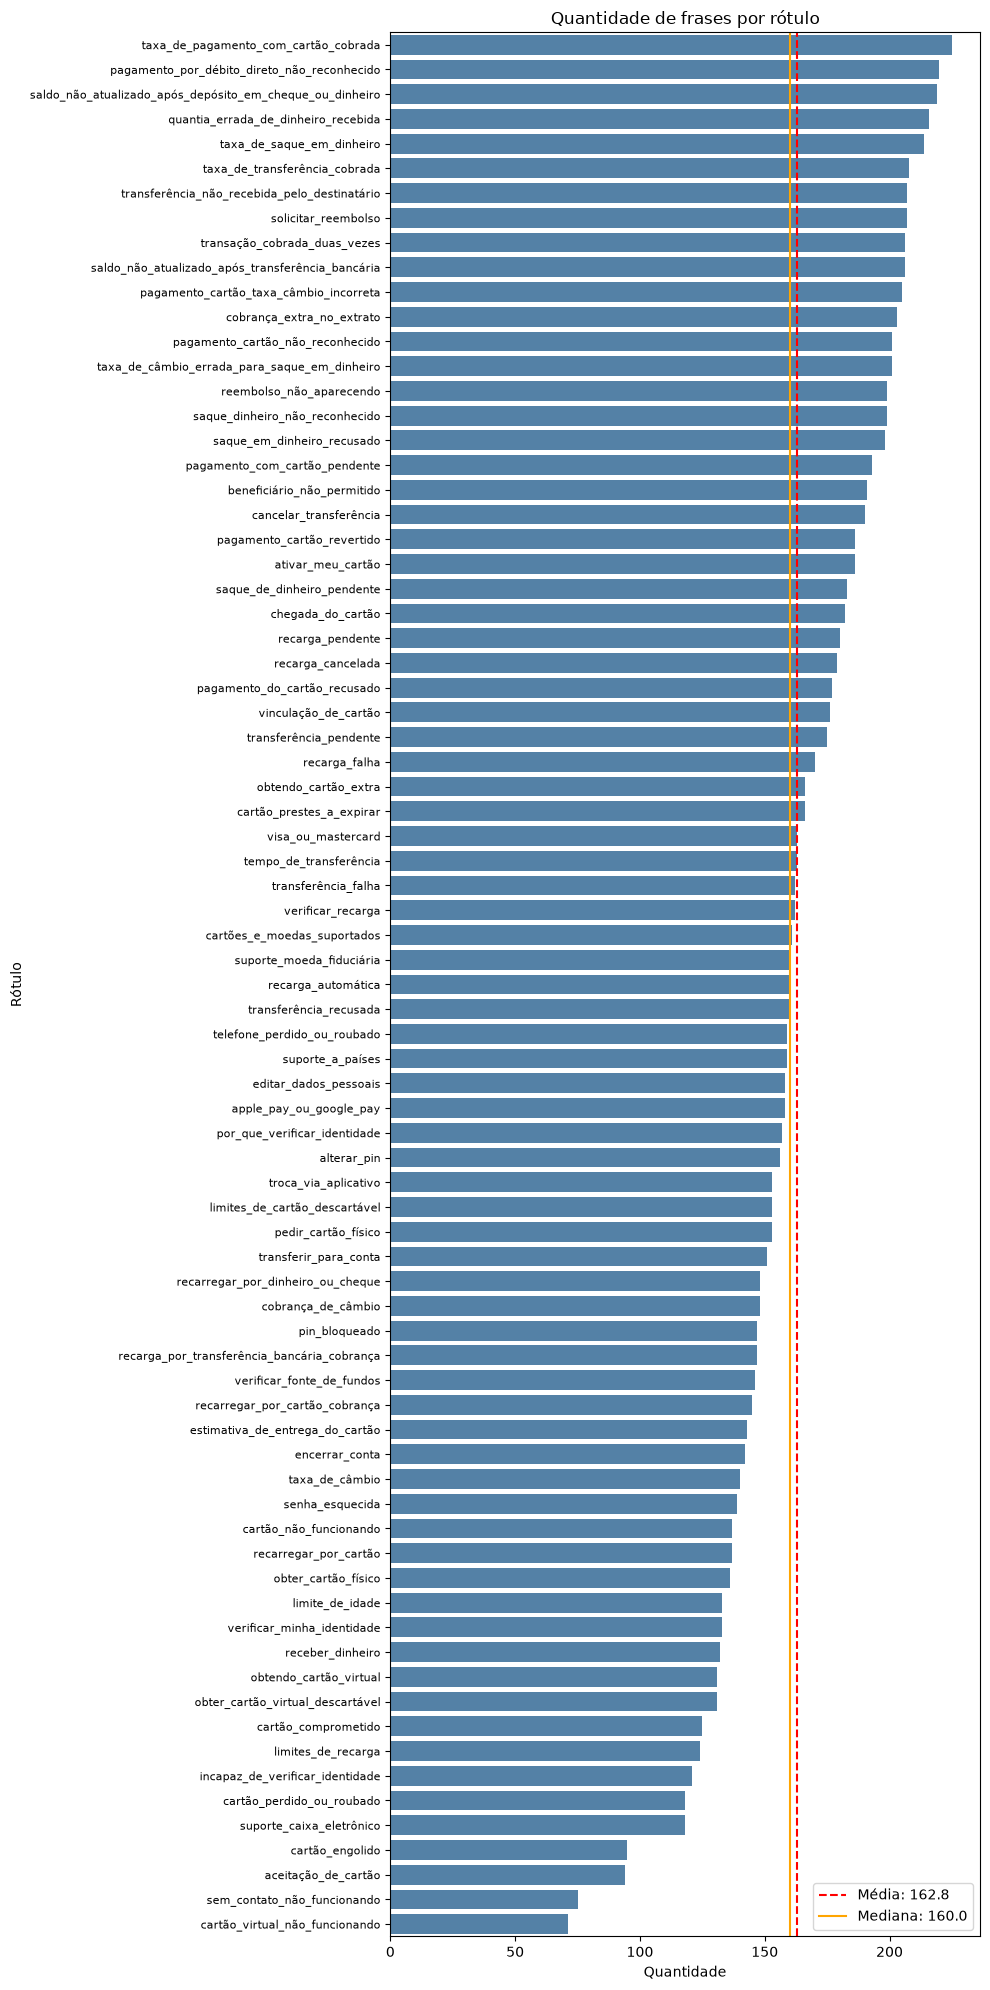

,Estatística,Valor
0,Nº de classes,77.00
1,Mínimo,71.00
2,Máximo,225.00
3,Média,162.83
4,Mediana,160.00
5,Desvio padrão,33.65
6,Razão maior/menor,3.17


In [4]:
valores_rotulo = df['rotulo'].value_counts()

media = valores_rotulo.mean()
mediana = valores_rotulo.median()

fig, ax = plt.subplots(figsize=(10, 20))

sns.barplot(
    x=valores_rotulo.values,
    y=valores_rotulo.index.astype(str),
    orient='h',
    color='steelblue',
    ax=ax
)

ax.axvline(media, color='red', linestyle='--', linewidth=1.5, label=f'Média: {media:.1f}')
ax.axvline(mediana, color='orange', linestyle='-', linewidth=1.5, label=f'Mediana: {mediana:.1f}')

ax.set_title('Quantidade de frases por rótulo')
ax.set_xlabel('Quantidade')
ax.set_ylabel('Rótulo')
ax.tick_params(axis='y', labelsize=8)
ax.legend()

plt.tight_layout()
plt.show()

estatisticas = pd.DataFrame({
    'Estatística': ['Nº de classes', 'Mínimo', 'Máximo', 'Média', 'Mediana',
                    'Desvio padrão', 'Razão maior/menor'],
    'Valor': [
        valores_rotulo.size,
        valores_rotulo.min(),
        valores_rotulo.max(),
        media,
        mediana,
        valores_rotulo.std(),
        valores_rotulo.max() / valores_rotulo.min(),
    ]
})

estatisticas['Valor'] = estatisticas['Valor'].round(2)
estatisticas

Existe desbalanceamento moderado entre as classes. A classe com menor quantidade de frases tem 71 elementos (`cartão_virtual_não_funcionando`), e a de maior tem 225 (`taxa_de_pagamento_com_cartão_cobrada`). A razão entre os dois é de 3,2.

Por isso, mais adiante farei a divisão estratificada entre o treino e teste, para os dois conjuntos manterem a mesma proporção de cada rótulo. Além disso, também usarei a métrica F1-macro para avaliação dos modelos, pois diferente da acurácia, que é dominada pelas classes com mais frases, o F1-macro calcula o desempenho de cada classe separadamente e tira a média simples, dando o mesmo peso a todas. Assim, um mal desempenho em um rótulo com poucas frases não passará despercebido.

#### 1.1 Quantidade de `caracteres` e `palavras` por frase por Rótulo

In [5]:
# Criando colunas de contagem n_caracteres e n_palavras
df['n_caracteres'] = df['frase'].str.len()
df['n_palavras'] = df['frase'].str.split().str.len()
df

,frase,rotulo,n_caracteres,n_palavras
0,Ainda estou esperando pelo meu cartão?,chegada_do_cartão,38,6
1,O que posso fazer se meu cartão ainda não cheg...,chegada_do_cartão,69,14
2,Eu tenho esperado por mais de uma semana. O ca...,chegada_do_cartão,68,13
3,Posso rastrear meu cartão enquanto está em pro...,chegada_do_cartão,63,10
4,"Como eu posso saber se vou receber meu cartão,...",chegada_do_cartão,70,14
...,...,...,...,...
12533,Em quais países você atualmente faz negócios?,suporte_a_países,45,7
12534,"Se eu não estiver no Reino Unido, ainda posso ...",suporte_a_países,62,12
12535,Quantos países vocês atendem ou oferecem suporte?,suporte_a_países,49,7
12536,Quais são os países em que você atua?,suporte_a_países,37,8


In [6]:
# Describe das novas colunas
df[['n_caracteres', 'n_palavras']].describe(percentiles=[0.1,0.25, 0.5,0.75, 0.90])

,n_caracteres,n_palavras
count,12538.000000,12538.000000
mean,66.813128,11.513639
std,42.825678,7.361744
min,12.000000,2.000000
10%,34.000000,6.000000
25%,42.000000,7.000000
50%,54.000000,9.000000
75%,72.000000,13.000000
90%,117.300000,20.000000
max,489.000000,78.000000


O maior outlier tem 489 caracteres e 78 palavras. Exibindo essa linha:

In [7]:
pd.set_option('display.max_colwidth', None)
index_max = df['n_caracteres'].idxmax()
pd.DataFrame(df.iloc[index_max])

,3801
frase,"Entre em contato conosco sobre os resultados importantes da verificação, que podem levar de 10 minutos a uma hora. Se os resultados da verificação falharem, verifique novamente para garantir que todas as suas imagens estejam claras -- certifique-se de que suas fotos não tenham reflexos ou distorções. Observação: Essas fotos precisam ser legíveis também. Você também precisa ter 18 anos ou mais. É necessário ser residente da Suíça ou da Área Econômica Europeia para abrir uma nova conta."
rotulo,incapaz_de_verificar_identidade
n_caracteres,489
n_palavras,78


Essa é uma resposta padrão do serviço bancário, não do usuário, o que indica que devem existir mais frases assim no dataset

##### **Boxplots**
**Caracteres x rótulo**

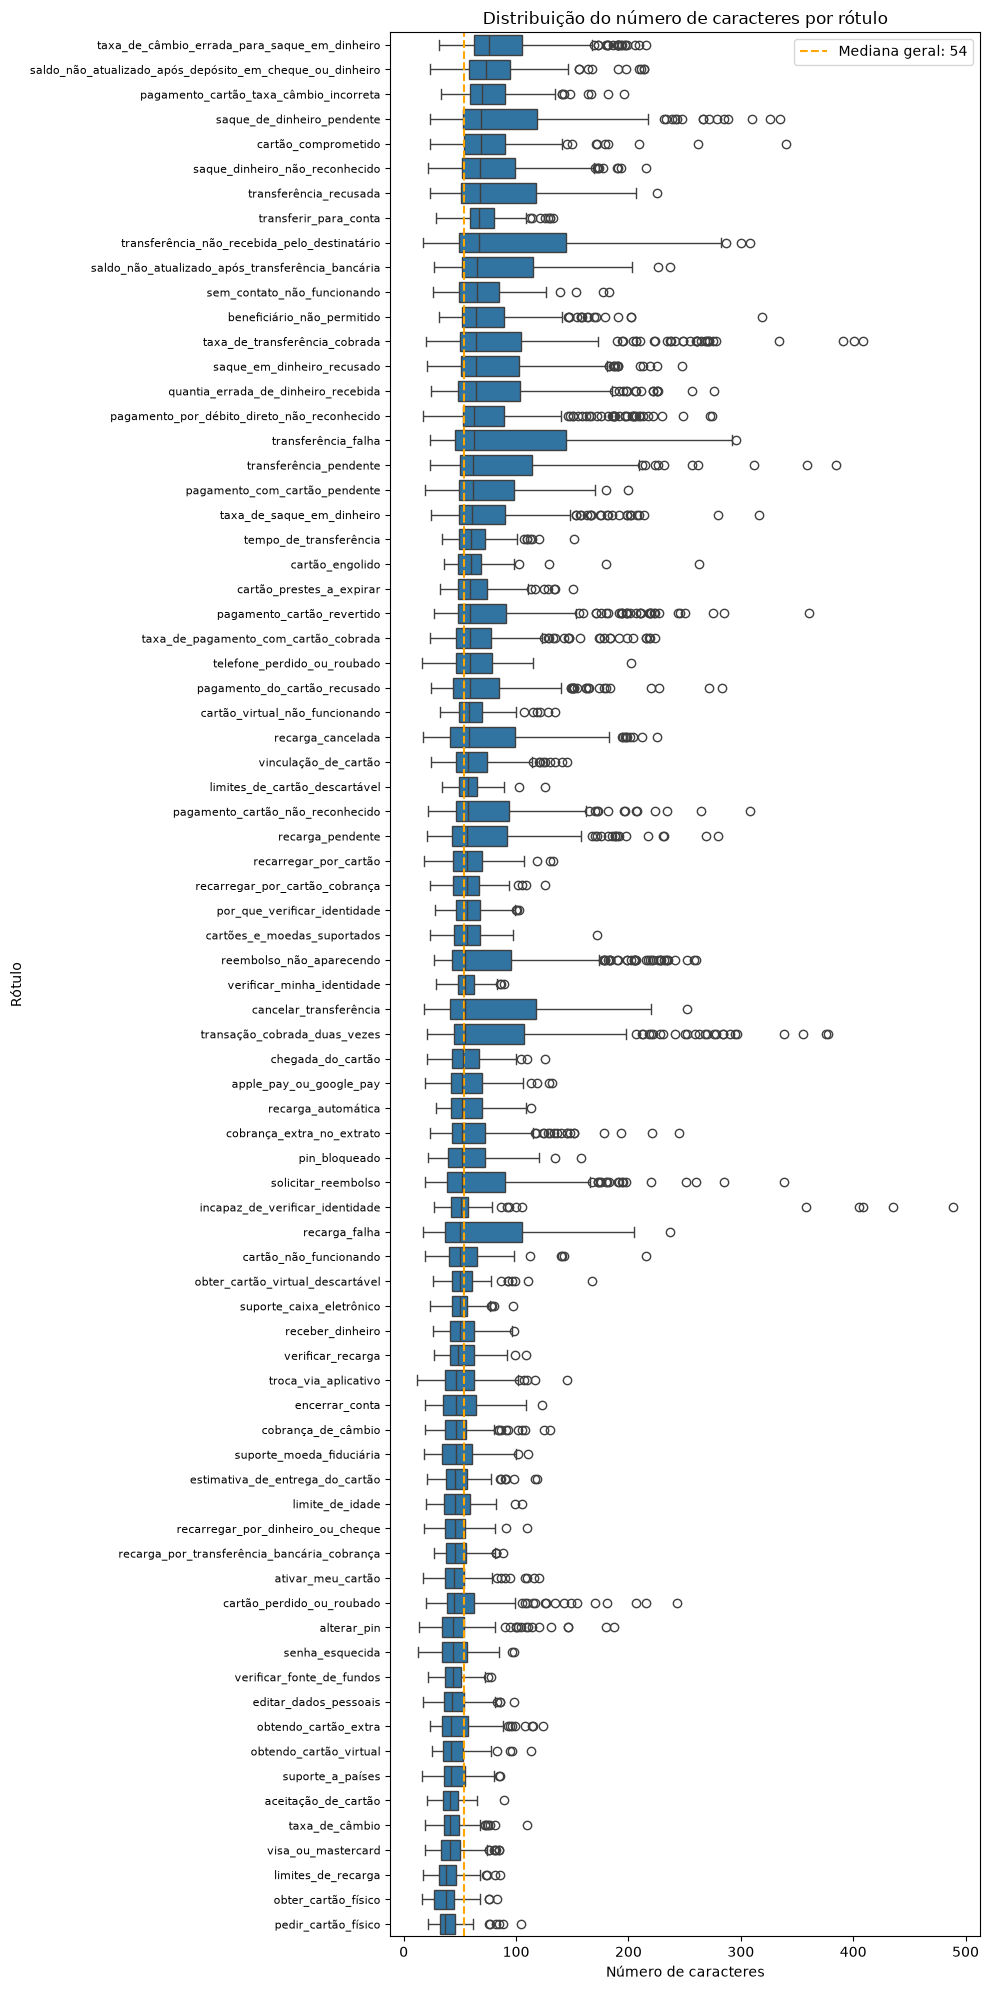

In [8]:
# Boxplots da quantidade de caracateres em cada rótulo
ordem = df.groupby('rotulo')['n_caracteres'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 20))

sns.boxplot(data=df, x='n_caracteres', y='rotulo', ax=ax, order=ordem)

ax.axvline(df['n_caracteres'].median(), color='orange', linestyle='--',
           label=f"Mediana geral: {df['n_caracteres'].median():.0f}")

ax.set_title('Distribuição do número de caracteres por rótulo')
ax.set_xlabel('Número de caracteres')
ax.set_ylabel('Rótulo')
ax.tick_params(axis='y', labelsize=8)
ax.legend()

plt.tight_layout()
plt.show()



**Palavras x rótulo**

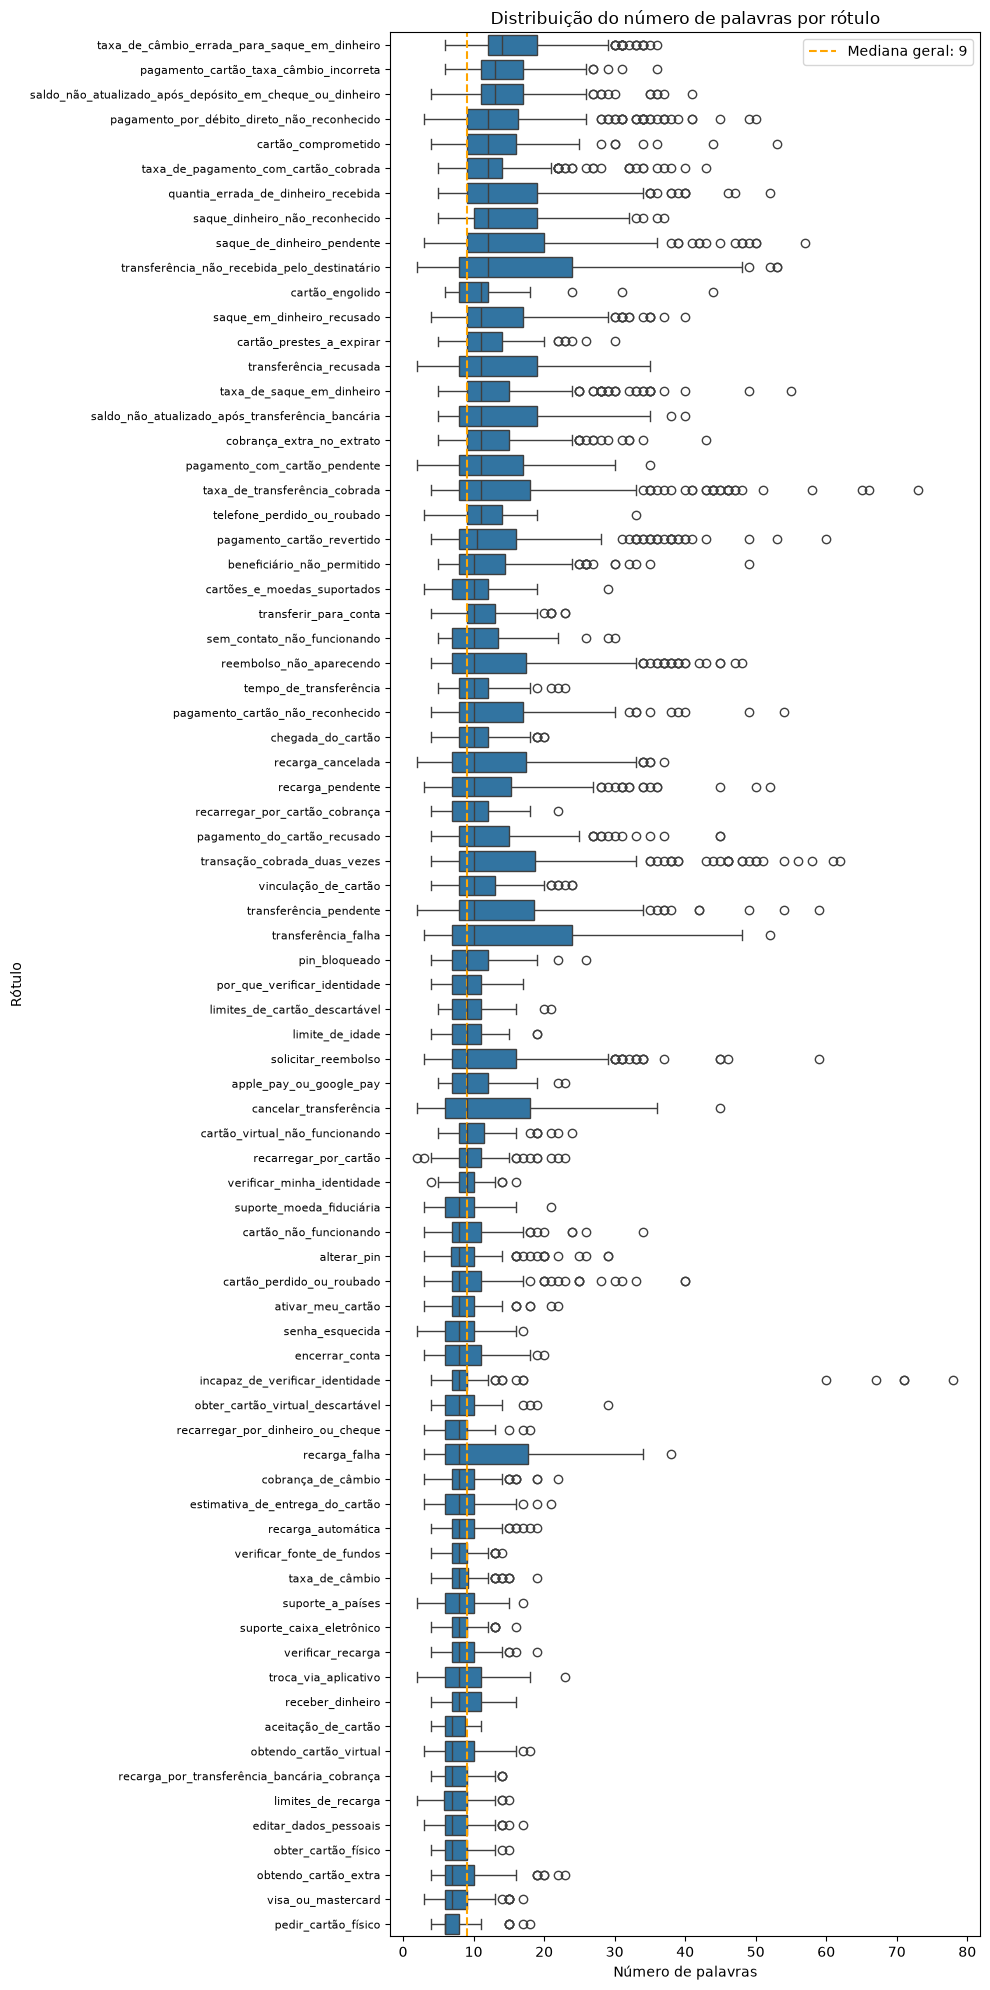

In [9]:
# Boxplots da quantidade de palavras em cada rótulo
ordem = df.groupby('rotulo')['n_palavras'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 20))

sns.boxplot(data=df, x='n_palavras', y='rotulo', ax=ax, order=ordem)

ax.axvline(df['n_palavras'].median(), color='orange', linestyle='--',
           label=f"Mediana geral: {df['n_palavras'].median():.0f}")

ax.set_title('Distribuição do número de palavras por rótulo')
ax.set_xlabel('Número de palavras')
ax.set_ylabel('Rótulo')
ax.tick_params(axis='y', labelsize=8)
ax.legend()

plt.tight_layout()
plt.show()

##### **Tabela das medianas**

In [10]:
display(pd.DataFrame(df.groupby('rotulo')['n_caracteres'].median().sort_values(ascending=False)))
display(pd.DataFrame(df.groupby('rotulo')['n_palavras'].median().sort_values(ascending=False)))

,n_caracteres
rotulo,
taxa_de_câmbio_errada_para_saque_em_dinheiro,76.0
saldo_não_atualizado_após_depósito_em_cheque_ou_dinheiro,73.0
pagamento_cartão_taxa_câmbio_incorreta,70.0
saque_de_dinheiro_pendente,69.0
cartão_comprometido,69.0
...,...
taxa_de_câmbio,41.0
visa_ou_mastercard,41.0
limites_de_recarga,38.0


,n_palavras
rotulo,
taxa_de_câmbio_errada_para_saque_em_dinheiro,14.0
pagamento_cartão_taxa_câmbio_incorreta,13.0
saldo_não_atualizado_após_depósito_em_cheque_ou_dinheiro,13.0
pagamento_por_débito_direto_não_reconhecido,12.0
cartão_comprometido,12.0
...,...
editar_dados_pessoais,7.0
obter_cartão_físico,7.0
obtendo_cartão_extra,7.0


Os boxplots indicam que o tamanho das frases varia conforme o rótulo. A mediana de caracteres por rótulo vai de 37 a 76, e a de palavras por rótulo vai de 6 a 14, ambos com o menor valor sendo da classe `pedir_cartão_físico`, e o maior da `taxa_de_câmbio_errada_para_saque_em_dinheiro`.

Rótulos de pedidos simples tendem a ter frases curtas, e rótulos que envolvem explicar um problema, frases longas.

##### **Top 30 maiores frases**

In [11]:
df.nlargest(30, 'n_caracteres').reset_index()

,index,frase,rotulo,n_caracteres,n_palavras
0,3801,"Entre em contato conosco sobre os resultados importantes da verificação, que podem levar de 10 minutos a uma hora. Se os resultados da verificação falharem, verifique novamente para garantir que todas as suas imagens estejam claras -- certifique-se de que suas fotos não tenham reflexos ou distorções. Observação: Essas fotos precisam ser legíveis também. Você também precisa ter 18 anos ou mais. É necessário ser residente da Suíça ou da Área Econômica Europeia para abrir uma nova conta.",incapaz_de_verificar_identidade,489,78
1,3816,"Saber sobre os resultados da sua verificação conosco pode levar de 10 minutos a aproximadamente uma hora. Se esta verificação de fato falhou, verifique novamente para garantir que suas imagens estão claras. Certifique-se também de que suas fotos de documentos não tenham desfoque ou reflexo. Elas precisam ser legíveis. Você também deve ter no mínimo 18 anos e ser residente da Suíça ou da Área Econômica Europeia para abrir uma conta.",incapaz_de_verificar_identidade,435,71
2,3795,"Pode levar entre 10 minutos e uma hora antes de recebermos uma resposta sobre o resultado da verificação. Por favor, tente novamente se a verificação falhar. Certifique-se de verificar duas vezes se as imagens estão nítidas e se todas as fotos de documentos são legíveis, sem desfoque ou brilho. Você precisa ter 18 anos ou mais e morar na área econômica europeia ou morar na Suíça para poder abrir uma conta.",incapaz_de_verificar_identidade,409,71
3,7089,"Olá! Sou um estudante universitário estudando no exterior e percebi que, ao tentar fazer a conferência do meu orçamento para este mês, havia taxas extras que eu não esperava. Por que isso acontece? Tenho essa conta há anos e não tive problemas até agora; pode ser que nem seja culpa de vocês, já que sou novo em viagens internacionais e finanças, mas queria verificar para o caso de um erro ter sido cometido!",taxa_de_transferência_cobrada,409,73
4,3790,"Você receberá nossa resposta sobre os resultados da verificação em um prazo de 10 minutos a uma hora. Se esses resultados de verificação falharem, por favor, verifique novamente para garantir que suas imagens estão claras e sem reflexo ou desfoque; suas fotos precisam estar totalmente legíveis. Você precisa ter 18 anos ou mais e ser residente na Suíça ou na Área Econômica Europeia para criar uma conta.",incapaz_de_verificar_identidade,405,67
5,7010,"Eu transferi 7.000 para um destinatário fora da UE e eles receberam um valor menor do que eu enviei. Infelizmente, agora preciso enviar uma transferência adicional para o destinatário para que ele possa receber o valor total que enviei inicialmente. Não tenho certeza do porquê eles receberam um valor menor do que eu enviei inicialmente, mas você poderia verificar isso e me informar o que aconteceu?",taxa_de_transferência_cobrada,401,66
6,11735,"Oi, por favor, me ajude, pois eu transferi uma quantia, mas o destinatário não recebeu o mesmo valor. Ele recebeu um pouco menos. Devido a isso, preciso transferir a diferença novamente. Eu transferi o dinheiro, mas a conta do beneficiário foi creditada com um valor menor. Agora eu preciso transferir a diferença do valor. Acho que há algum problema, você poderia verificar isso, por favor?",taxa_de_transferência_cobrada,391,65
7,5816,"As transferências podem aparecer como pendentes por até um dia enquanto são processadas por um dos nossos processadores de pagamento. Em seguida, elas serão enviadas para as contas dos beneficiários. Por favor, verifique também se você inseriu os dados da conta corretamente. Transferências SEPA podem levar até dois dias úteis, e transferências SWIFT podem levar até cinco dias úteis.",transferência_pendente,385,59
8,6158,"Olá, sou um estudante universitário que recentemente participei da reunião de ex-alunos do meu colégio em um restaurante local. Eu paguei com meu cartão de crédito e agora meu histórico de transações reflete uma segunda cobrança aparentemente da 

##### **Top 30 menores frases**

In [12]:
df.nsmallest(30, 'n_caracteres')

,frase,rotulo,n_caracteres,n_palavras
10095,Mudar moeda.,troca_via_aplicativo,12,2
4740,Senha perdida,senha_esquecida,13,2
6723,Mudar meu PIN?,alterar_pin,14,3
3879,O PIN do cartão?,obter_cartão_físico,16,4
5148,o telefone sumiu,telefone_perdido_ou_roubado,16,3
6757,Mudando meu PIN.,alterar_pin,16,3
9673,Países atendidos,suporte_a_países,16,2
2218,Posso recarregar?,limites_de_recarga,17,2
3194,Recarga revertida,recarga_cancelada,17,2
4488,Qual é a palavra?,pagamento_por_débito_direto_não_reconhecido,17,4


Dentre as 30 frases mais longas, algumas não são frases do usuário, mas sim respostas padrão do serviço bancário. Além disso, algumas aparecem repetidamente no dataset com número de caracteres distintos. Exemplos:

- As transferências podem levar até um dia para serem processadas
- As transferências podem aparecer como pendentes por até um dia
- Entre em contato conosco sobre os resultados
- Saber sobre os resultados da sua verificação
- Você receberá nossa resposta
- Se você estiver aguardando verificação, pode levar de 10 a 60 minutos para obter
- Pode levar entre 10 minutos e uma hora antes de recebermos

Então, excluo esses casos do dataset

In [13]:
prefixos = (
    'As transferências podem levar até um dia para serem processadas',
    'As transferências podem aparecer como pendentes por até um dia',
    'Entre em contato conosco sobre os resultados',
    'Saber sobre os resultados da sua verificação',
    'Você receberá nossa resposta',
    'Se você estiver aguardando verificação, pode levar de 10 a 60 minutos para obter',
    'Pode levar entre 10 minutos e uma hora antes de recebermos',
)

mascara = df['frase'].str.strip().str.startswith(prefixos, na=False)

print(f'Linhas removidas: {mascara.sum()}')
df = df[~mascara].reset_index(drop=True)

Linhas removidas: 8


### 2. Vocabulário

#### 2.1 Stopwords

Dentre as palavras mais frequentes, espera-se que muitas delas sejam **stopwords**

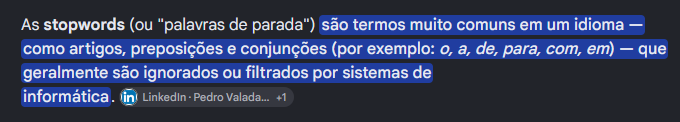

Essa categoria de palavras provavelmente aparece na maioria dos rótulos e não ajudará a distinguí-los. Por isso, neste notebook farei algumas análises usando tanto o conjunto de dados com e sem stopwords. Além disso, também farei essa comparação no teste dos modelos para ver se há ganho de performance.

OBS: Usarei a lista de `stopwords`  da biblioteca `nltk`
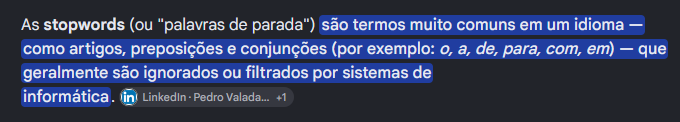

In [14]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
stop_pt = set(stopwords.words('portuguese'))

print('Lista de stopwords')
stop_pt

Lista de stopwords


{'a',
 'ao',
 'aos',
 'aquela',
 'aquelas',
 'aquele',
 'aqueles',
 'aquilo',
 'as',
 'até',
 'com',
 'como',
 'da',
 'das',
 'de',
 'dela',
 'delas',
 'dele',
 'deles',
 'depois',
 'do',
 'dos',
 'e',
 'ela',
 'elas',
 'ele',
 'eles',
 'em',
 'entre',
 'era',
 'eram',
 'essa',
 'essas',
 'esse',
 'esses',
 'esta',
 'estamos',
 'estar',
 'estas',
 'estava',
 'estavam',
 'este',
 'esteja',
 'estejam',
 'estejamos',
 'estes',
 'esteve',
 'estive',
 'estivemos',
 'estiver',
 'estivera',
 'estiveram',
 'estiverem',
 'estivermos',
 'estivesse',
 'estivessem',
 'estivéramos',
 'estivéssemos',
 'estou',
 'está',
 'estávamos',
 'estão',
 'eu',
 'foi',
 'fomos',
 'for',
 'fora',
 'foram',
 'forem',
 'formos',
 'fosse',
 'fossem',
 'fui',
 'fôramos',
 'fôssemos',
 'haja',
 'hajam',
 'hajamos',
 'havemos',
 'haver',
 'hei',
 'houve',
 'houvemos',
 'houver',
 'houvera',
 'houveram',
 'houverei',
 'houverem',
 'houveremos',
 'houveria',
 'houveriam',
 'houvermos',
 'houverá',
 'houverão',
 'houverí

**Stopwords de negação** \
Essa lista de stopwords incluem palavras de negação, como `não`, `nem` e `sem`. Removê-las seria um problema, pois elas podem inverter o sentido das frases.

**Exemplo:**

* meu cartão não chegou -> meu cartão chegou

Além disso, alguns rótulos são definidos pela negação, como:
- `pagamento_cartão_não_reconhecido`
- `sem_contato_não_funcionando`
- `cartão_não_funcionando`

No caso do `sem`, há um motivo a mais: em `sem_contato_não_funcionando`, "sem contato" é o nome do pagamento por aproximação, e não uma negação. Removê-lo quebraria esse termo.

Por isso, retiro **`não`, `nem` e `sem`** da lista de stopwords.

In [15]:
negacoes = {'não', 'nem', 'sem'}
stop_pt = set(stopwords.words('portuguese')) - negacoes

#### 2.2 Palavras mais e menos frequentes no dataset

Primeiro, crio os vocabulários do Dataset com e sem stopwords.

Para a tokenização, usarei o token pattern `r'(?u)\b\w+\b'`, e manterei isso como padrão no resto do projeto.

- `r'(?u)'`: Ativa o suporte a Unicode. Isso garante que letras com acentos, cedilhas e caracteres de outros idiomas (como á, é, ç, ñ) sejam reconhecidas corretamente como letras.
- `\b`: Representa uma fronteira de palavra (word boundary), marcando o início da palavra.
- `\w+`: Captura uma ou mais ocorrências de caracteres alfanuméricos (letras de A-Z, números de 0-9 e o caractere de sublinhado _).
- `\b`: Fecha a fronteira, marcando o fim da palavra.

Resumidamente, essa tokenização divide o texto pegando apenas sequências de letras e números, ignorando pontuações (como pontos, vírgulas, exclamações e hífens).
-  Exemplo:
	- Texto original: "Olá, mundo! O ano é 2026."
	- Tokens gerados: ['Olá', 'mundo', 'O', 'ano', 'é', '2026']

In [16]:
# Criando vocabulário do dataset com stopwords com CountVectorizer()
from sklearn.feature_extraction.text import CountVectorizer

# token_pattern mantém palavras de 1 caractere (o, a, é, 1), que o padrão do CountVectorizer descarta
vectorizer = CountVectorizer(token_pattern=r'(?u)\b\w+\b')
bag = vectorizer.fit_transform(df['frase'])
names = vectorizer.get_feature_names_out()

# Tabela de frequência por palavra
tabela_vocabulario = pd.DataFrame({
    'palavra': names,
    'frequencia': bag.sum(axis=0).A1,
}).sort_values('frequencia', ascending=False).reset_index(drop=True)

tabela_vocabulario_sem_stopw = tabela_vocabulario[~tabela_vocabulario['palavra'].isin(stop_pt)].reset_index(drop=True)

print('Vocabulário com stopwords')
display(tabela_vocabulario)
print()
print('Vocabulário sem stopwords')
display(tabela_vocabulario_sem_stopw)

Vocabulário com stopwords


,palavra,frequencia
0,que,5507
1,eu,4746
2,meu,4104
3,de,3924
4,o,3784
...,...,...
3348,45,1
3349,50,1
3350,6,1
3351,zero,1



Vocabulário sem stopwords


,palavra,frequencia
0,cartão,3459
1,não,3429
2,dinheiro,2160
3,posso,1713
4,conta,1681
...,...,...
3215,45,1
3216,50,1
3217,6,1
3218,zero,1


**Função reutilizável do Gráfico de nuvem:** \
Essa é um função que plota o gráfico de núvem, e foi adaptada para poder plotar tanto o conjunto com `stopwords`, quanto o sem.

In [17]:
from wordcloud import WordCloud

def grafico_nuvem(tabela, titulo):
    freq = tabela.set_index('palavra')['frequencia'].to_dict()

    nuvem = WordCloud(
        width=1600,
        height=800,
        background_color='white',
        colormap='viridis',
        max_words=100,
        random_state=42,
    ).generate_from_frequencies(freq)

    plt.figure(figsize=(14, 7))
    plt.imshow(nuvem, interpolation='bilinear')
    plt.axis('off')
    plt.title(titulo)
    plt.show()

##### **Vocabulário com stopwords**


Quantidade de palavras total: 144308
Tamanho do vocabulário (palavras distintas): 3353
Quantidade de palavras que aparecem apenas 1x: 1225
% de palavras que aparecem apenas 1x no vocabulário: 36.5


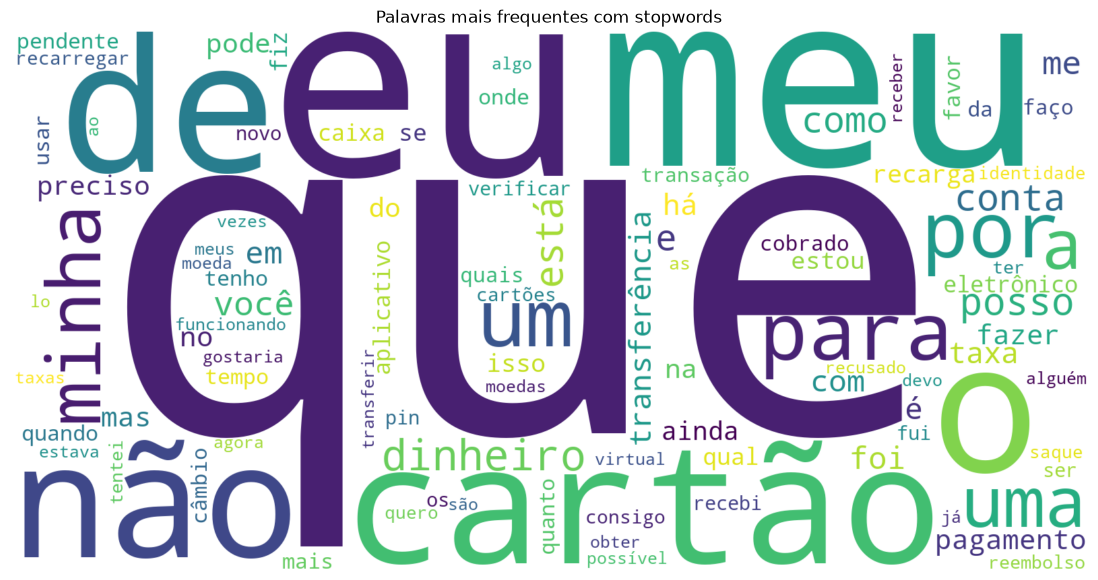

,palavra,frequencia
0,que,5507
1,eu,4746
2,meu,4104
3,de,3924
4,o,3784
5,cartão,3459
6,não,3429
7,para,3050
8,um,3006
9,por,2815


In [18]:
aparece_1x = (tabela_vocabulario['frequencia'] == 1).sum()
print()
print('Quantidade de palavras total:', tabela_vocabulario['frequencia'].sum())
print('Tamanho do vocabulário (palavras distintas):', len(tabela_vocabulario))
print('Quantidade de palavras que aparecem apenas 1x:', aparece_1x)
print('% de palavras que aparecem apenas 1x no vocabulário:', (aparece_1x/len(tabela_vocabulario)).round(3)*100)

grafico_nuvem(tabela_vocabulario, 'Palavras mais frequentes com stopwords')

from IPython.display import display_html

# Função pra plotar o gráfico das palavras mais e menos frequentes lado a lado
def display_lado_a_lado(*dfs, titulos=()):
    html = ''
    for df_, titulo in zip(dfs, titulos):
        html += (
            df_.style.set_table_attributes('style="display:inline-block; margin-right:40px; vertical-align:top"')
            .set_caption(titulo)
            .to_html()
        )
    display_html(html, raw=True)

print()
display_lado_a_lado(tabela_vocabulario.head(20), tabela_vocabulario.tail(20), titulos=['20 palavras mais frequentes', '20 palavras menos frequentes'],)


##### **Vocabulário sem stopwords**


Quantidade de palavras total: 77517
Tamanho do vocabulário: 3220



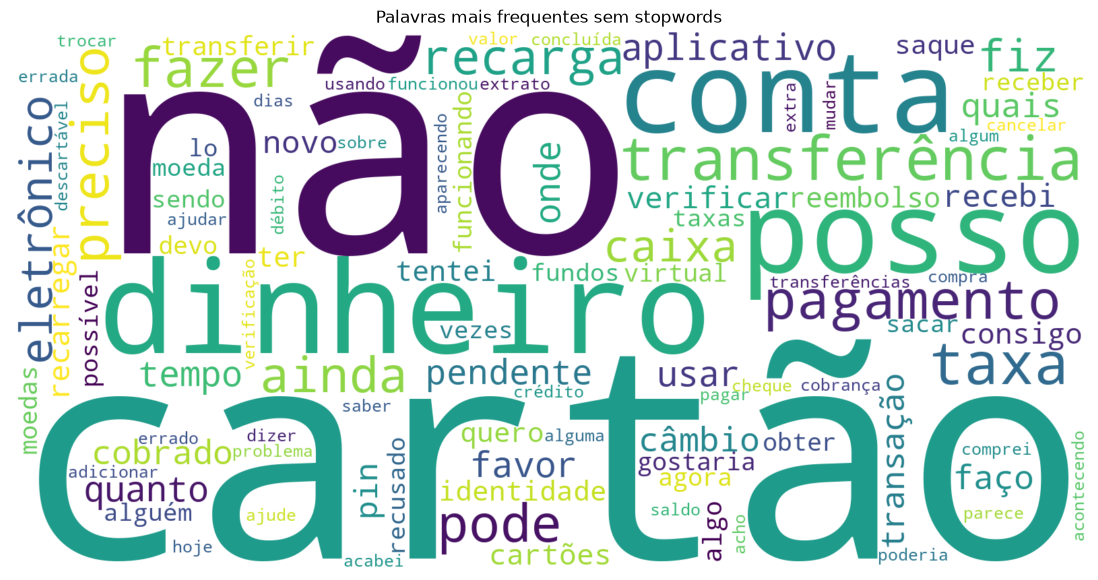

20 palavras mais frequentes


,palavra,frequencia
0,cartão,3459
1,não,3429
2,dinheiro,2160
3,posso,1713
4,conta,1681
5,transferência,1102
6,taxa,1057
7,pagamento,914
8,fazer,901
9,pode,839


In [19]:
print()
print('Quantidade de palavras total:', tabela_vocabulario_sem_stopw['frequencia'].sum())
print('Tamanho do vocabulário:', len(tabela_vocabulario_sem_stopw))
print()
grafico_nuvem(tabela_vocabulario_sem_stopw, 'Palavras mais frequentes sem stopwords')

print('20 palavras mais frequentes')
display(tabela_vocabulario_sem_stopw.head(20))

Olhando para o gráfico e tabela de palavras **sem stopwords**, realmente pode-se perceber que aparecem palavras mais informativas dentre as mais frequentes, considerando o contexto do dataset, por isso faz sentido testar os 2 conjuntos na modelagem. Dito isso, em seguida analiso as palavras mais frequentes por rótulo

##### **Caracteres numéricos**

     -

#### 2.3 N-gramas mais frequentes x Rótulo

#### 2.3.1 Unigrama

##### **Top 5 palavras mais frequentes por rótulo**
Função reutilizável para exibir a tabela de cada conjunto

In [20]:
def exibir_top5(plvs, coluna='palavra'):
    top_contagem = {}

    for classe in df['rotulo'].unique():
        contagem = plvs[plvs['rotulo'] == classe][coluna].value_counts().head(5)
        top_contagem[classe] = []
        for palavra, n in contagem.items():
            top_contagem[classe].append(f'{palavra} ({n})')

    display(pd.DataFrame.from_dict(top_contagem, orient='index', columns=['1ª', '2ª', '3ª', '4ª', '5ª']).head(50))

In [21]:
# Crio uma tabela que cada linha é uma palavra. Então, uma frase com 5 palavras do dataset
# vira 5 linhas, uma pra cada palavra, também com o rótulo da frase indicado

palavras = df[['rotulo', 'frase']].copy()
palavras['palavra'] = palavras['frase'].str.lower().str.findall(r'\w+')
palavras = palavras.explode('palavra')
palavras_sem_stopw = palavras[~palavras['palavra'].isin(stop_pt)]

- **Com stopwords**

In [22]:
exibir_top5(palavras)

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,cartão (177),meu (121),o (87),que (85),eu (68)
vinculação_de_cartão,cartão (177),eu (116),meu (110),como (82),aplicativo (65)
taxa_de_câmbio,de (151),câmbio (129),taxa (66),taxas (61),a (54)
pagamento_cartão_taxa_câmbio_incorreta,a (205),taxa (196),de (196),câmbio (180),que (133)
cobrança_extra_no_extrato,que (158),uma (147),de (129),1 (105),por (101)
saque_de_dinheiro_pendente,dinheiro (168),pendente (130),que (128),está (114),em (97)
suporte_moeda_fiduciária,moedas (104),quais (64),você (57),para (51),posso (49)
estimativa_de_entrega_do_cartão,cartão (81),meu (71),para (53),tempo (40),entrega (38)
recarga_automática,recarga (83),automática (72),posso (57),a (52),de (45)
cartão_não_funcionando,cartão (131),meu (118),não (88),que (60),está (57)


- **Sem stopwords**

In [23]:
exibir_top5(palavras_sem_stopw)

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,cartão (177),ainda (60),não (59),novo (56),rastrear (29)
vinculação_de_cartão,cartão (177),aplicativo (65),lo (53),faço (52),posso (50)
taxa_de_câmbio,câmbio (129),taxa (66),taxas (61),quais (17),saber (16)
pagamento_cartão_taxa_câmbio_incorreta,taxa (196),câmbio (180),errada (72),comprei (64),incorreta (39)
cobrança_extra_no_extrato,1 (105),extra (84),taxa (72),cobrança (67),extrato (55)
saque_de_dinheiro_pendente,dinheiro (168),pendente (130),saque (94),ainda (87),não (74)
suporte_moeda_fiduciária,moedas (104),quais (64),posso (49),fiduciárias (46),moeda (30)
estimativa_de_entrega_do_cartão,cartão (81),tempo (40),entrega (38),quanto (35),posso (30)
recarga_automática,recarga (83),automática (72),posso (57),automaticamente (42),dinheiro (38)
cartão_não_funcionando,cartão (131),não (88),funcionando (44),usar (19),fazer (18)


Rótulos com temas parecidos tendem a compartilhar as palavras mais frequentes. Por exemplo:

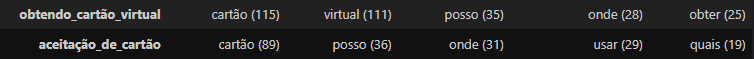

Isso indica que a frequência das palavras sozinha não é suficiente para distinguir esses rótulos, e que pares como esses devem ser os mais difíceis para o modelo.
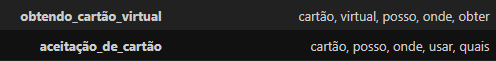

#### 2.3.2 Bi-gramas
Um bigrama é um par de palavras vizinhas na frase. Por exemplo, para "meu cartão não chegou", os bigramas são:
- `meu cartão`
- `cartão não`
- `não chegou`

##### **Top 5 bigramas mais frequentes por rótulo**

In [24]:
# Função que recebe a lista de palavras de uma frase e devolve os bigramas dela
def gerar_bigramas(lista_palavras):
    return [f'{p1} {p2}' for p1, p2 in zip(lista_palavras, lista_palavras[1:])]

# Crio uma tabela que cada linha é um bigrama de cada frase
bigramas = df[['rotulo', 'frase']].copy()
bigramas['palavras'] = bigramas['frase'].str.lower().str.findall(r'\w+')

bigramas_sem_stopw = bigramas.copy()
bigramas_sem_stopw['palavras'] = bigramas_sem_stopw['palavras'].apply(lambda plvs: [p for p in plvs if p not in stop_pt])

bigramas['bigrama'] = bigramas['palavras'].apply(gerar_bigramas)
bigramas = bigramas.explode('bigrama').dropna(subset=['bigrama'])

bigramas_sem_stopw['bigrama'] = bigramas_sem_stopw['palavras'].apply(gerar_bigramas)
bigramas_sem_stopw = bigramas_sem_stopw.explode('bigrama').dropna(subset=['bigrama'])

- **Com stopwords**

In [25]:
exibir_top5(bigramas, 'bigrama')

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,meu cartão (72),novo cartão (55),meu novo (49),ainda não (47),cartão que (38)
vinculação_de_cartão,meu cartão (80),como faço (48),no aplicativo (44),faço para (44),novo cartão (38)
taxa_de_câmbio,de câmbio (126),taxa de (65),taxas de (61),a taxa (40),suas taxas (33)
pagamento_cartão_taxa_câmbio_incorreta,de câmbio (173),taxa de (169),a taxa (158),que a (30),que comprei (29)
cobrança_extra_no_extrato,de 1 (88),por que (78),na minha (53),meu extrato (51),uma taxa (49)
saque_de_dinheiro_pendente,caixa eletrônico (67),em dinheiro (64),está pendente (58),saque em (57),ainda está (53)
suporte_moeda_fiduciária,quais moedas (47),moedas fiduciárias (46),fiduciárias são (16),posso ter (13),várias moedas (13)
estimativa_de_entrega_do_cartão,meu cartão (66),quanto tempo (33),a entrega (18),eu preciso (17),estados unidos (15)
recarga_automática,recarga automática (71),de recarga (33),posso fazer (19),opção de (18),adicionar dinheiro (15)
cartão_não_funcionando,meu cartão (118),não está (38),cartão não (37),está funcionando (32),o que (23)


- **Sem stopwords**

In [26]:
exibir_top5(bigramas_sem_stopw, 'bigrama')

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,novo cartão (55),ainda não (47),cartão ainda (28),não recebi (25),rastrear cartão (24)
vinculação_de_cartão,novo cartão (38),reativar cartão (23),vincular novo (22),vincular cartão (20),encontrei cartão (19)
taxa_de_câmbio,taxa câmbio (65),taxas câmbio (61),quais taxas (14),gostaria saber (6),saber taxa (5)
pagamento_cartão_taxa_câmbio_incorreta,taxa câmbio (169),câmbio errada (37),item comprei (25),comprei algo (25),câmbio pagamento (21)
cobrança_extra_no_extrato,taxa extra (42),extra 1 (39),1 extrato (23),cobrança extra (21),cobrança 1 (17)
saque_de_dinheiro_pendente,caixa eletrônico (67),saque dinheiro (62),ainda pendente (38),dinheiro caixa (33),dinheiro ainda (22)
suporte_moeda_fiduciária,quais moedas (50),moedas fiduciárias (46),posso ter (13),várias moedas (13),manter dinheiro (11)
estimativa_de_entrega_do_cartão,quanto tempo (33),estados unidos (15),cartão chegar (11),posso esperar (10),receber cartão (10)
recarga_automática,recarga automática (71),posso fazer (19),opção recarga (16),adicionar dinheiro (15),fazer recarga (15)
cartão_não_funcionando,cartão não (44),não funcionando (42),usar cartão (18),não consigo (13),fazer cartão (12)


`meu cartão` é o bigrama mais frequente em 12 dos 77 rótulos.

Analisando os bigramas, eles confirmam que a decisão de manter as negações fora das stopwords é positiva, pois alguns termos como `não fiz`, `não chegou`, `não recebi` e `não funcionando` aparecem no top 5 de vários rótulos.

Porém, muitos rótulos do mesmo tema compartilham o bigrama top 1, exemplo:

- `taxa câmbio`: os 3 rótulos de câmbio (`taxa_de_câmbio`, `pagamento_cartão_taxa_câmbio_incorreta` e `taxa_de_câmbio_errada_para_saque_em_dinheiro`)
- `caixa eletrônico`: é o mais frequente em 5 rótulos, como `saque_de_dinheiro_pendente`, `saque_em_dinheiro_recusado` e `cartão_engolido`
- `verificar identidade` e `verificação identidade`: `por_que_verificar_identidade` e `incapaz_de_verificar_identidade`

OBS: no conjunto sem stopwords, alguns bigramas unem palavras que não eram vizinhas na frase original, como `taxa câmbio` ("taxa de câmbio") e `pagamento aproximação` ("pagamento por aproximação").

#### 2.3.3 Tri-gramas
Um trigrama é uma sequência de três palavras vizinhas na frase. Por exemplo, para "meu cartão não chegou", os trigramas são:
- `meu cartão não`
- `cartão não chegou`

##### **Top 5 trigramas mais frequentes por rótulo**

In [27]:
# Função que recebe a lista de palavras de uma frase e devolve os trigramas dela
def gerar_trigramas(lista_palavras):
    return [f'{p1} {p2} {p3}' for p1, p2, p3 in zip(lista_palavras, lista_palavras[1:], lista_palavras[2:])]

# Crio uma tabela que cada linha é um trigrama de cada frase
trigramas = df[['rotulo', 'frase']].copy()
trigramas['palavras'] = trigramas['frase'].str.lower().str.findall(r'\w+')

trigramas_sem_stopw = trigramas.copy()
trigramas_sem_stopw['palavras'] = trigramas_sem_stopw['palavras'].apply(lambda plvs: [p for p in plvs if p not in stop_pt])

trigramas['trigrama'] = trigramas['palavras'].apply(gerar_trigramas)
trigramas = trigramas.explode('trigrama').dropna(subset=['trigrama'])

trigramas_sem_stopw['trigrama'] = trigramas_sem_stopw['palavras'].apply(gerar_trigramas)
trigramas_sem_stopw = trigramas_sem_stopw.explode('trigrama').dropna(subset=['trigrama'])

- **Com stopwords**

In [28]:
exibir_top5(trigramas, 'trigrama')

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,meu novo cartão (49),o cartão que (24),ainda não chegou (22),cartão que você (21),cartão ainda não (18)
vinculação_de_cartão,como faço para (43),faço para vincular (18),reativar meu cartão (15),encontrei meu cartão (14),meu novo cartão (14)
taxa_de_câmbio,taxa de câmbio (65),taxas de câmbio (61),a taxa de (39),suas taxas de (33),as taxas de (21)
pagamento_cartão_taxa_câmbio_incorreta,taxa de câmbio (169),a taxa de (138),que a taxa (30),de câmbio estava (27),item que comprei (24)
cobrança_extra_no_extrato,extra de 1 (39),na minha fatura (35),uma taxa extra (31),no meu extrato (28),há uma cobrança (23)
saque_de_dinheiro_pendente,saque em dinheiro (55),ainda está pendente (36),um saque em (27),no caixa eletrônico (26),meu saque em (24)
suporte_moeda_fiduciária,quais moedas fiduciárias (28),moedas fiduciárias são (16),fiduciárias são suportadas (9),moedas fiduciárias você (9),dinheiro em várias (7)
estimativa_de_entrega_do_cartão,do meu cartão (12),quando posso esperar (10),receber meu cartão (9),qual é o (9),para a entrega (9)
recarga_automática,de recarga automática (31),opção de recarga (16),a recarga automática (14),a opção de (12),adicionar dinheiro automaticamente (10)
cartão_não_funcionando,meu cartão não (35),não está funcionando (31),cartão não está (22),que meu cartão (19),usar meu cartão (16)


- **Sem stopwords**

In [29]:
exibir_top5(trigramas_sem_stopw, 'trigrama')

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,cartão ainda não (27),ainda não chegou (22),ainda não recebi (18),rastrear cartão enviou (10),não recebi novo (9)
vinculação_de_cartão,vincular novo cartão (22),lo volta aplicativo (9),posso reativar cartão (9),faço vincular cartão (8),faço vincular novo (8)
taxa_de_câmbio,quais taxas câmbio (14),saber taxa câmbio (5),saber quais taxas (4),taxa câmbio estrangeira (4),saber taxas câmbio (3)
pagamento_cartão_taxa_câmbio_incorreta,taxa câmbio errada (37),taxa câmbio pagamento (21),taxa câmbio incorreta (21),taxa câmbio correta (12),taxa câmbio aplicada (10)
cobrança_extra_no_extrato,taxa extra 1 (19),cobrança extra 1 (14),extra 1 extrato (10),extra 1 fatura (9),taxa extra fatura (8)
saque_de_dinheiro_pendente,dinheiro caixa eletrônico (33),caixa eletrônico ainda (18),saque dinheiro pendente (16),saque dinheiro ainda (15),tentei sacar dinheiro (14)
suporte_moeda_fiduciária,quais moedas fiduciárias (30),moedas fiduciárias suportadas (10),dinheiro várias moedas (7),moedas fiduciárias posso (7),fiduciárias posso usar (7)
estimativa_de_entrega_do_cartão,quanto tempo leva (8),entrega estados unidos (7),quanto tempo levará (7),quanto tempo vai (6),tempo vai levar (5)
recarga_automática,opção recarga automática (15),fazer recarga automática (13),adicionar dinheiro automaticamente (10),posso fazer recarga (10),função recarga automática (9)
cartão_não_funcionando,cartão não funcionando (27),cartão não funciona (10),não consigo usar (7),consigo usar cartão (7),não consigo fazer (6)


Com stopwords, muitos trigramas do topo ainda são formados em volta de stopwords, como `como faço para`, `que eu não` e `na minha conta`.

Sem stopwords, os trigramas separam alguns rótulos que os bigramas não separavam. Por exemplo, `taxa_de_câmbio` e `pagamento_cartão_taxa_câmbio_incorreta`, que compartilhavam o bigrama `taxa câmbio`, agora têm trigramas diferentes no topo: `quais taxas câmbio` e `taxa câmbio errada`. Também aparecem expressões completas, como `cartão prestes expirar`, `cobrado duas vezes` e `não devolveu cartão`.

Porém, os pares mais parecidos continuam compartilhando o trigrama top 1, exemplo:

- `taxa câmbio errada`: `pagamento_cartão_taxa_câmbio_incorreta` e `taxa_de_câmbio_errada_para_saque_em_dinheiro`
- `dinheiro caixa eletrônico`: é o mais frequente em 4 rótulos de saque, como `saque_em_dinheiro_recusado` e `taxa_de_saque_em_dinheiro`
- `cartão virtual descartável`: `obter_cartão_virtual_descartável` e `cartão_virtual_não_funcionando`

Por isso, na modelagem vale testar tanto `ngram_range=(1, 3)`, quanto `(1, 2)`, mas com `min_df=2` para descartar os termos que aparecem uma vez só, e mantê-lo apenas se superar o `(1, 2)` no F1-macro.

OBS: assim como nos bigramas, remover as stopwords antes de formar os trigramas junta palavras que não eram vizinhas na frase, o que gera alguns trigramas sem sentido, como `lo volta aplicativo` e `american express apple`.

### 3. Palavras mais distintivas de cada classe usando `TF-IDF`

O que é TF-IDF?

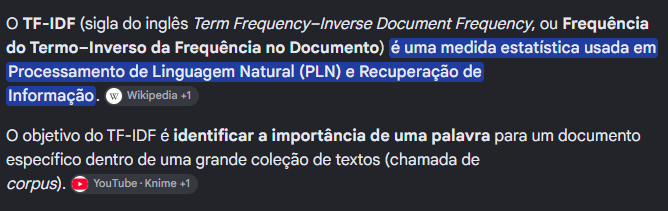

A fórmula do TF-IDF para cada palavra é:

$\text{TF-IDF}(t, d) = \text{TF}(t, d) \times \text{IDF}(t)$

- O **TF** é quantas vezes o termo $t$ aparece no documento $d$
- O **IDF** é $\log(N / n_t)$, em que $N$ é o total de documentos e $n_t$ é em quantos deles o termo aparece

No `sklearn`, o IDF tem uma suavização:

$\text{IDF}(t) = \ln\frac{1+N}{1+n_t} + 1$

O +1 da fração evita divisão por zero, e o +1 final faz uma palavra que está em todos os documentos ficar com IDF = 1 ao em vez de 0. Assim, ela não é zerada, também não ganha peso alto.

A ideia é dar um peso alto para uma palavra se ela for frequente em um documento e rara nos demais, e peso baixo se aparecer em quase todos, como as stopwords.

Para fazer essa comparação entre as classes, cada documento será a união de todas as frases de um rótulo, então o TF-IDF destaca os termos que distinguem um rótulo dos outros.

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Agrupo o df por rótulo e uno todas as frases de cada um em uma só para cada
docs = df.groupby('rotulo')['frase'].apply(' '.join)

#### 3.1 Unigrama
Primeiro, calculo a matriz TF-IDF das palavras, com e sem stopwords. Cada linha é um rótulo, cada coluna é uma palavra do vocabulário, e o valor é o TF-IDF da palavra naquele rótulo.

Uso `norm=None` para o valor ser exatamente TF × IDF, sem normalizar pelo tamanho do documento.

In [31]:
# Matriz TF-IDF Com stopwords

vectorizer_tf_idf = TfidfVectorizer(norm=None, token_pattern=r'(?u)\b\w+\b')
tf_idf = vectorizer_tf_idf.fit_transform(docs)
tf_idf_words = tf_idf.toarray()
tfidf_classe = pd.DataFrame(tf_idf.toarray(), index=docs.index, columns=vectorizer_tf_idf.get_feature_names_out())
print()
print()
print()

# Matriz TF-IDF Sem stopwords
vectorizer_tf_idf_stopw = TfidfVectorizer(norm=None, stop_words=list(stop_pt), token_pattern=r'(?u)\b\w+\b')
tf_idf_stopw = vectorizer_tf_idf_stopw.fit_transform(docs)
tf_idf_words_stopw = tf_idf_stopw.toarray()
tfidf_stopw_classe = pd.DataFrame(tf_idf_words_stopw, index=docs.index, columns=vectorizer_tf_idf_stopw.get_feature_names_out())

##### **Top 5 palavras mais distintivas por rótulo**
Função reutilizável para exibir a tabela de cada matriz. Para cada rótulo, exibo os 5 termos de maior TF-IDF.

In [32]:
def exibir_top5_tfidf(matriz):
    top_tfidf = {}

    for classe in df['rotulo'].unique():
        maiores = matriz.loc[classe].nlargest(5)
        top_tfidf[classe] = []
        for termo, valor in maiores.items():
            top_tfidf[classe].append(f'{termo} ({valor:.1f})')

    tabela = pd.DataFrame.from_dict(top_tfidf, orient='index', columns=['1ª', '2ª', '3ª', '4ª', '5ª'])

    # Exibe os 77 rótulos, sem o pandas cortar a tabela
    with pd.option_context('display.max_rows', None):
        display(tabela)

- **Com stopwords**

In [33]:
exibir_top5_tfidf(tfidf_classe)

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,cartão (220.5),meu (122.6),rastrear (108.7),novo (100.9),ainda (98.6)
vinculação_de_cartão,cartão (220.5),vincular (204.4),encontrei (121.2),eu (116.0),meu (111.4)
taxa_de_câmbio,câmbio (422.8),taxa (162.8),taxas (161.6),de (151.0),suas (94.8)
pagamento_cartão_taxa_câmbio_incorreta,câmbio (589.9),taxa (483.4),errada (219.9),a (205.0),de (196.0)
cobrança_extra_no_extrato,1 (416.9),extra (234.5),libra (178.8),taxa (177.6),que (158.0)
saque_de_dinheiro_pendente,pendente (373.3),saque (297.0),dinheiro (242.7),caixa (195.3),eletrônico (177.5)
suporte_moeda_fiduciária,moedas (328.6),fiduciárias (214.5),moeda (91.6),eur (91.3),manter (89.9)
estimativa_de_entrega_do_cartão,entrega (124.5),cartão (100.9),tempo (74.4),meu (71.9),entregue (68.8)
recarga_automática,automática (269.8),recarga (219.8),automaticamente (178.8),auto (74.6),opção (61.4)
cartão_não_funcionando,cartão (163.2),meu (119.5),não (97.5),funcionando (90.7),está (63.2)


- **Sem stopwords**

In [34]:
exibir_top5_tfidf(tfidf_stopw_classe)

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,cartão (220.5),rastrear (108.7),novo (100.9),ainda (98.6),enviou (86.2)
vinculação_de_cartão,cartão (220.5),vincular (204.4),encontrei (121.2),perdido (100.8),aplicativo (97.9)
taxa_de_câmbio,câmbio (422.8),taxa (162.8),taxas (161.6),calculadas (28.0),quais (21.5)
pagamento_cartão_taxa_câmbio_incorreta,câmbio (589.9),taxa (483.4),errada (219.9),comprei (173.9),incorreta (123.2)
cobrança_extra_no_extrato,1 (416.9),extra (234.5),libra (178.8),taxa (177.6),cobrança (151.8)
saque_de_dinheiro_pendente,pendente (373.3),saque (297.0),dinheiro (242.7),caixa (195.3),eletrônico (177.5)
suporte_moeda_fiduciária,moedas (328.6),fiduciárias (214.5),moeda (91.6),eur (91.3),manter (89.9)
estimativa_de_entrega_do_cartão,entrega (124.5),cartão (100.9),tempo (74.4),entregue (68.8),chegar (62.1)
recarga_automática,automática (269.8),recarga (219.8),automaticamente (178.8),auto (74.6),opção (61.4)
cartão_não_funcionando,cartão (163.2),não (97.5),funcionando (90.7),funcionar (41.9),quebrado (34.8)


##### **Rótulos parecidos**
As duas linhas com 3 gráficos em cada abaixo são trios de rótulos com o mesmo tema, que possuem as mesmas palavras mais frequentes:

 - `câmbio` e `taxa` para o primeiro trio (1º linha)
 - `identidade` para o segundo trio (2º linha)

O gráfico mostra os 8 termos de maior TF-IDF de cada um, sem stopwords.

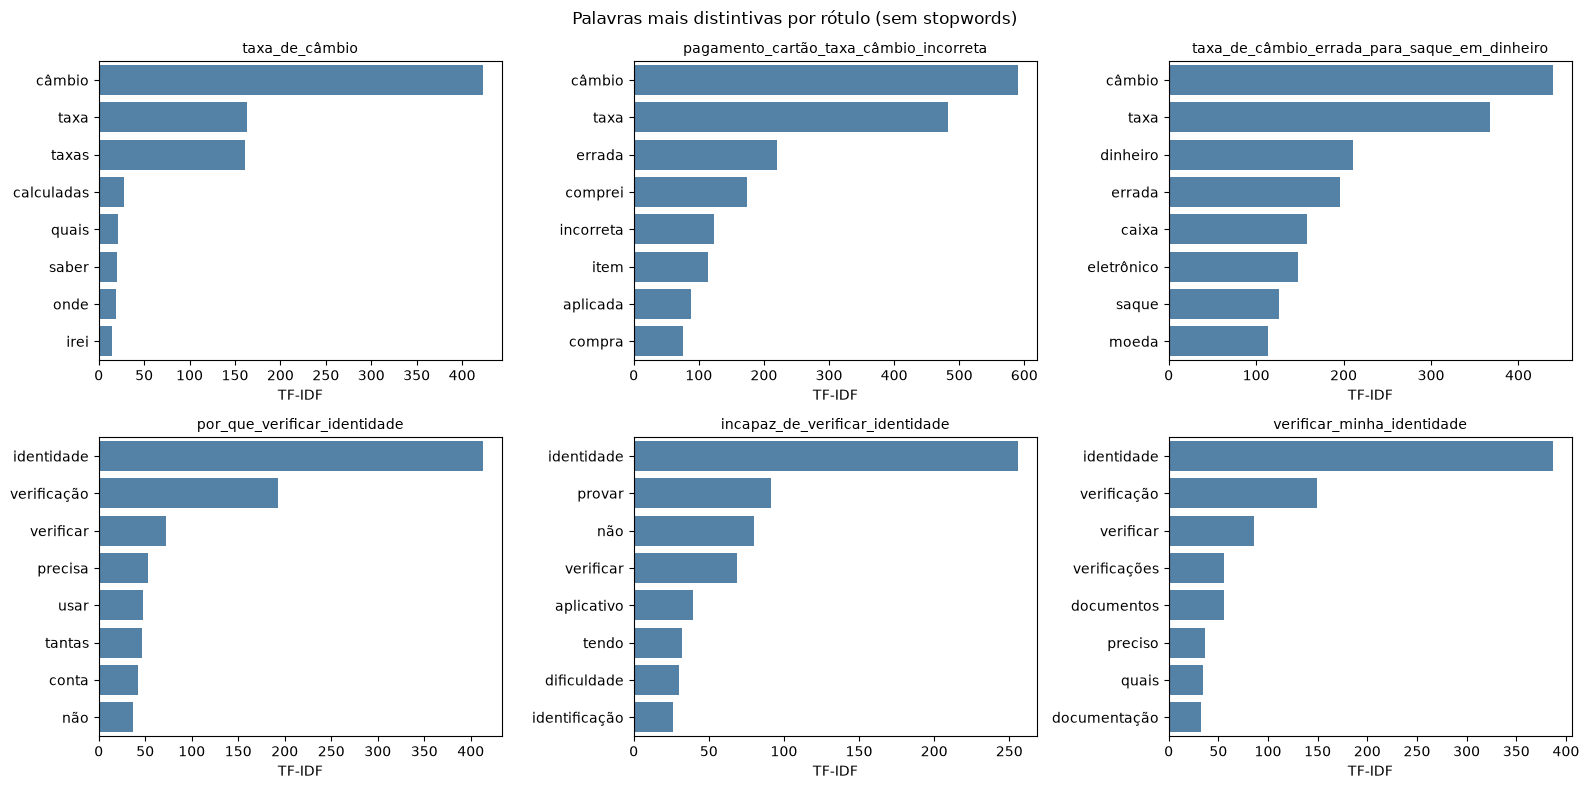

In [35]:
rotulos_parecidos = [
    'taxa_de_câmbio',
    'pagamento_cartão_taxa_câmbio_incorreta',
    'taxa_de_câmbio_errada_para_saque_em_dinheiro',
    'por_que_verificar_identidade',
    'incapaz_de_verificar_identidade',
    'verificar_minha_identidade',
]

# Função que plota um painel com os n termos de maior TF-IDF de cada rótulo da lista
def grafico_top_tfidf(matriz, rotulos, titulo, n=8):
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))

    for ax, classe in zip(axes.flat, rotulos):
        maiores = matriz.loc[classe].nlargest(n)
        sns.barplot(x=maiores.values, y=maiores.index.astype(str), orient='h', color='steelblue', ax=ax)
        ax.set_title(classe, fontsize=10)
        ax.set_xlabel('TF-IDF')
        ax.set_ylabel('')

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

grafico_top_tfidf(tfidf_stopw_classe, rotulos_parecidos, 'Palavras mais distintivas por rótulo (sem stopwords)')

Com o TF-IDF, o topo de cada rótulo passa a ter palavras mais específicas do que na contagem simples. Em muitos deles, a primeira palavra agora é praticamente o nome do rótulo. Por exemplo: `ativar`, `expirar`, `idade`, `beneficiário`, `senha`, `visa`, `reembolso`.

Entretanto, palavras muito frequentes continuam no topo e rótulos do mesmo tema continuam compartilhando o top 1. Nesses casos, o que diferenciam os rótulos é a distribuição do TF-IDF das outras palavras, como mostra o gráfico.

Para a modelagem, isso reforça o teste com e sem stopwords, e também vale testar o hiperparâmetro `sublinear_tf=True` no vetorizador `TfidfVectorizer`, que troca o TF por $1 + \ln(\text{TF})$ e reduz o peso das palavras muito repetidas.


#### 3.2 Bi-grama
Agora repito a análise com bigramas.

In [36]:
from sklearn.feature_extraction.text import TfidfTransformer

def matriz_tfidf(tabela, coluna):
    # Matriz de contagem: uma linha por rótulo e uma coluna por termo
    contagem = tabela.groupby(['rotulo', coluna]).size().unstack(fill_value=0)

    tfidf = TfidfTransformer(norm=None).fit_transform(contagem)
    return pd.DataFrame(tfidf.toarray(), index=contagem.index, columns=contagem.columns)

tfidf_bi_classe = matriz_tfidf(bigramas, 'bigrama')
tfidf_bi_stopw_classe = matriz_tfidf(bigramas_sem_stopw, 'bigrama')

print('Matriz TF-IDF de bigramas com stopwords:', tfidf_bi_classe.shape)
print('Matriz TF-IDF de bigramas sem stopwords:', tfidf_bi_stopw_classe.shape)

Matriz TF-IDF de bigramas com stopwords: (77, 23745)
Matriz TF-IDF de bigramas sem stopwords: (77, 22740)


##### **Top 5 bigramas mais distintivos por rótulo**

- **Com stopwords**

In [37]:
exibir_top5_tfidf(tfidf_bi_classe)

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,novo cartão (129.9),meu novo (126.6),ainda não (98.6),meu cartão (93.3),cartão que (91.7)
vinculação_de_cartão,para vincular (111.9),meu cartão (103.7),no aplicativo (90.7),novo cartão (89.7),vincular meu (76.6)
taxa_de_câmbio,de câmbio (429.8),taxas de (199.9),taxa de (186.7),suas taxas (123.7),a taxa (111.7)
pagamento_cartão_taxa_câmbio_incorreta,de câmbio (590.1),taxa de (485.3),a taxa (441.1),câmbio estava (119.2),estava errada (97.9)
cobrança_extra_no_extrato,de 1 (374.7),extra de (200.5),uma libra (149.2),taxa extra (132.7),meu extrato (131.8)
saque_de_dinheiro_pendente,caixa eletrônico (192.4),saque em (186.8),em dinheiro (183.8),está pendente (171.6),ainda está (152.2)
suporte_moeda_fiduciária,moedas fiduciárias (214.5),quais moedas (154.0),fiduciárias são (74.6),várias moedas (60.6),são suportadas (46.8)
estimativa_de_entrega_do_cartão,meu cartão (85.6),a entrega (76.6),quanto tempo (71.9),estados unidos (56.2),de entrega (47.8)
recarga_automática,recarga automática (302.3),de recarga (92.1),dinheiro automaticamente (65.3),opção de (56.9),a opção (47.4)
cartão_não_funcionando,meu cartão (153.0),cartão não (73.6),está funcionando (68.4),não está (58.1),nenhuma transação (34.1)


- **Sem stopwords**

In [38]:
exibir_top5_tfidf(tfidf_bi_stopw_classe)

,1ª,2ª,3ª,4ª,5ª
chegada_do_cartão,novo cartão (129.9),rastrear cartão (111.9),ainda não (98.6),cartão enviou (93.3),cartão ainda (85.5)
vinculação_de_cartão,vincular novo (102.6),reativar cartão (97.9),vincular cartão (93.3),novo cartão (89.7),encontrei cartão (88.6)
taxa_de_câmbio,taxa câmbio (243.6),taxas câmbio (228.6),quais taxas (41.4),saber taxa (23.3),câmbio estrangeira (17.0)
pagamento_cartão_taxa_câmbio_incorreta,taxa câmbio (633.3),câmbio errada (157.5),câmbio pagamento (97.9),câmbio incorreta (89.4),item comprei (89.1)
cobrança_extra_no_extrato,extra 1 (181.9),taxa extra (132.7),1 extrato (107.3),cobrança 1 (79.3),cobrança extra (71.6)
saque_de_dinheiro_pendente,saque dinheiro (195.9),caixa eletrônico (192.4),ainda pendente (116.1),dinheiro caixa (104.3),dinheiro pendente (79.4)
suporte_moeda_fiduciária,moedas fiduciárias (214.5),quais moedas (163.9),várias moedas (60.6),manter dinheiro (51.3),fiduciárias suportadas (46.6)
estimativa_de_entrega_do_cartão,quanto tempo (71.9),estados unidos (56.2),cartão chegar (46.8),data específica (37.3),cartão entregue (34.1)
recarga_automática,recarga automática (302.3),dinheiro automaticamente (65.3),opção recarga (63.5),recarregar automaticamente (46.6),fazer recarga (43.1)
cartão_não_funcionando,não funcionando (88.1),cartão não (81.8),cartão quebrado (38.3),usar cartão (37.1),nenhuma transação (34.1)


##### **Rótulos parecidos**
Os mesmos dois trios da seção anterior, agora com os 8 bigramas de maior TF-IDF de cada rótulo.

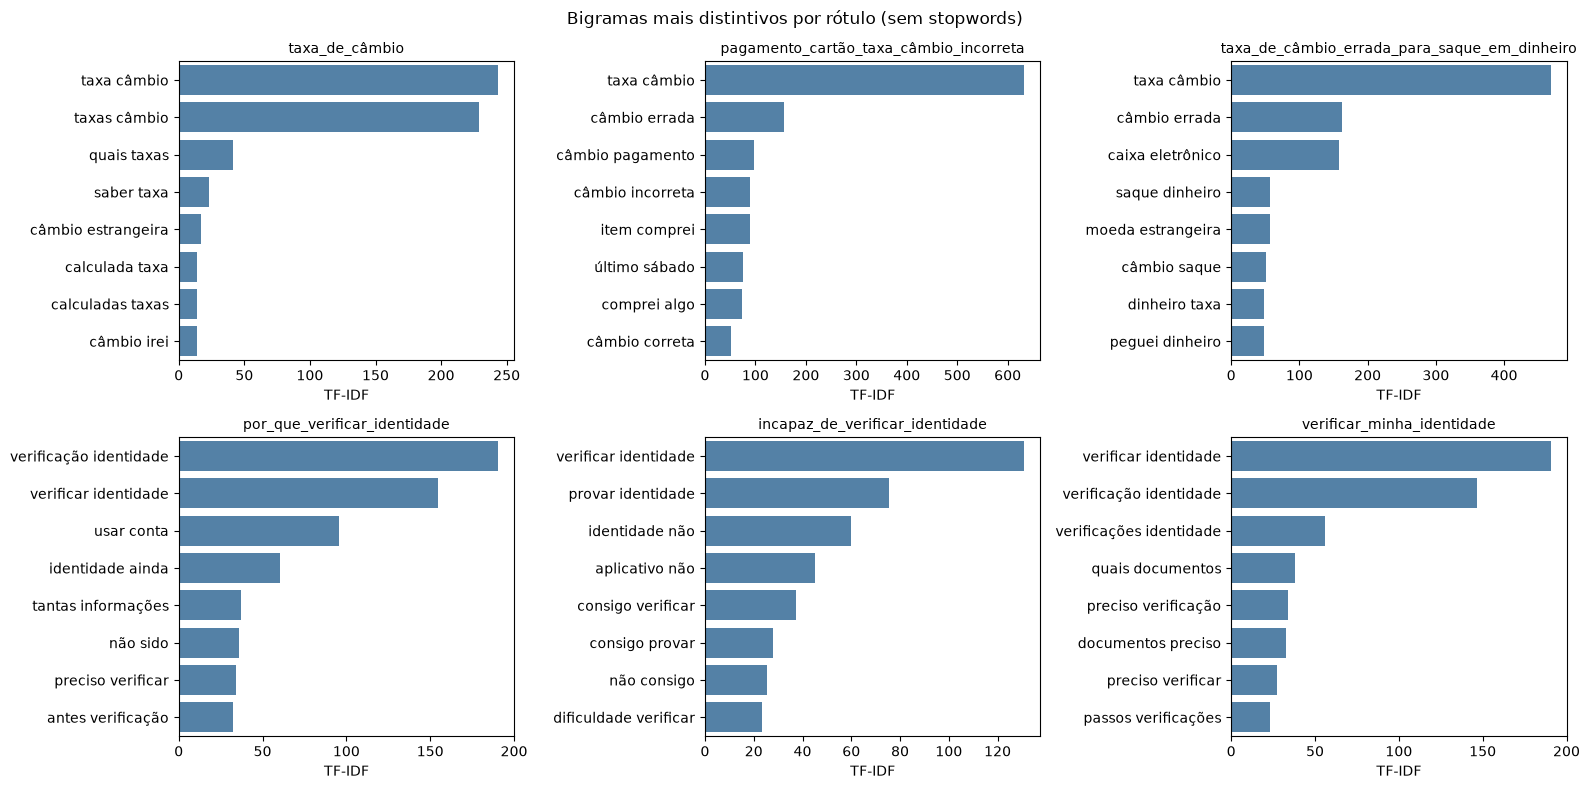

In [39]:
grafico_top_tfidf(tfidf_bi_stopw_classe, rotulos_parecidos, 'Bigramas mais distintivos por rótulo (sem stopwords)')

Os bigramas já conseguem separar vários rótulos que compartilhavam o top 1 nos unigramas da tabela sem stopwords. Exemplos:

- Os 3 rótulos com `pin` no topo agora têm `mudar pin` (`alterar_pin`), `desbloquear pin` (`pin_bloqueado`) e `pin cartão` (`obter_cartão_físico`)
- Os 7 rótulos com `transferência` no topo agora têm 7 bigramas diferentes, como `transferência recusada`, `transferência pendente`, `transferência falhou` e `transferência sepa`
- Os 4 rótulos com `recarga` no topo também ficam com 4 bigramas diferentes, como `recarga cancelada` e `código verificação`

As negações também aparecem entre os bigramas mais distintivos, como `não fiz`, `não reconheço`, `não funcionando`, `não recebeu` e `ainda não`.

### 4. Conclusões para a modelagem

**Dados**
- Após remover 8 respostas padrão do banco, restam 12.530 frases e 77 rótulos.
- O desbalanceamento é moderado: de 71 a 225 frases por rótulo (razão de 3,2). Por isso, a divisão entre treino e teste será estratificada e a métrica principal será o F1-macro.
- As frases são curtas, com mediana de 9 palavras, e o tamanho varia conforme o rótulo (mediana de 6 a 14 palavras).

**Pré-processamento a testar no `TfidfVectorizer`**
- **Stopwords:** com e sem, mantendo `não`, `nem` e `sem` fora da lista.
- **N-gramas:** `ngram_range=(1, 1)`, `(1, 2)` e `(1, 3)`, pois bigramas e trigramas separam rótulos que compartilham as mesmas palavras.
- **`min_df=2`:** para descartar termos que aparecem uma vez só, principalmente com trigramas. No vocabulário de palavras, 36,5% aparecem uma única vez.
- **`sublinear_tf=True`:** para reduzir o peso das palavras muito repetidas.

**Rótulos que devem ser mais difíceis**

Rótulos do mesmo tema compartilham os termos mais frequentes e distintivos, mesmo com bigramas e trigramas. São os candidatos aos erros mais comuns na matriz de confusão:
- **Câmbio:** `taxa_de_câmbio`, `pagamento_cartão_taxa_câmbio_incorreta` e `taxa_de_câmbio_errada_para_saque_em_dinheiro`
- **Identidade:** `por_que_verificar_identidade`, `incapaz_de_verificar_identidade` e `verificar_minha_identidade`
- **Caixa eletrônico:** `saque_de_dinheiro_pendente`, `saque_em_dinheiro_recusado`, `cartão_engolido`, `quantia_errada_de_dinheiro_recebida` e `taxa_de_saque_em_dinheiro`
- **Cartão virtual:** `obter_cartão_virtual_descartável` e `cartão_virtual_não_funcionando`

### 5. Salvar CSV para modelagem

In [40]:
df[['frase', 'rotulo']].to_csv('../data/processed/df_02.csv', index=False)
print(df.shape)

(12530, 4)
